# 04 · Regimes normais, perfis e limites por atributo (v7)
**CRISP-DM:** Modelagem

**Regimes normais (proposto):** para cada recurso e histórico, k-means nos 4 indicadores das janelas de 1 h; cada regime tem mediana e escala robusta (1,4826 × MAD) próprias. Um regime é **admissível** num contexto (tipo de dia × hora) se ocorreu em ≥ 5% das janelas desse contexto ou das horas vizinhas (± 1 h). O período é comparado ao regime admissível em que melhor se encaixa:

z = (valor − mediana do regime) / escala do regime, contado só no sentido desfavorável (volume nos dois sentidos; 4xx, 5xx e latência só na alta).

**Limite por atributo:** para cada tamanho de faixa L (15, 30 e 60 min), os z do histórico são calculados **fora da amostra** (validação cruzada com 4 blocos contíguos de tempo). O limite do indicador a no recurso r é o **percentil 95** desses z (mínimo 3), com c = 1.

**Decisão:** o período é **Residual** se, em todos os regimes admissíveis, algum indicador passa do seu limite; o **indicador responsável** é o que mais passou no regime admissível mais próximo.

Para cada **mês de teste** (agosto; setembro 1–20), os modelos são ajustados só com dados anteriores, em dois históricos: **3 meses** (principal) e **1 mês**. Comparações: perfil por contexto (v3/v5), regimes sem contexto, z-score global e semana anterior.


In [1]:
%run ./00_funcoes.ipynb

00_funcoes (v7) carregado · /home/wsl/gh/mestrado/claude9/v7


In [2]:
import pickle
jan1h = pd.read_parquet(RESULTADOS / "02_janelas_60min.parquet")
periodos = {60: jan1h}
for L in (15, 30):
    periodos[L] = pd.read_parquet(RESULTADOS / f"02_janelas_{L}min.parquet")
for L in periodos:
    periodos[L] = com_semana_anterior(periodos[L], periodos[L])

In [3]:
calib = {}
for mes in MESES_TESTE:
    for hist in HISTORICOS:
        per = periodo_treino(mes, hist)
        for nome, fab in METODOS.items():
            for L in FAIXAS_L:
                calib[(nome, L, mes, hist)] = calibrar(jan1h, periodos[L], fab, per)
        print(f"mês {mes} · histórico {hist} ({per[0]:%d/%m}–{per[1] - pd.Timedelta('1D'):%d/%m}) · alarmes no histórico (proposto, 15 min) = "
              f"{(calib[(PROPOSTO, 15, mes, hist)]['razao_cal'] > 1).mean():.1%}")

mês ago · histórico 3m (01/05–31/07) · alarmes no histórico (proposto, 15 min) = 8.0%


mês ago · histórico 1m (01/07–31/07) · alarmes no histórico (proposto, 15 min) = 9.9%


mês set · histórico 3m (01/06–31/08) · alarmes no histórico (proposto, 15 min) = 8.3%


mês set · histórico 1m (01/08–31/08) · alarmes no histórico (proposto, 15 min) = 8.7%


## Limites do método proposto (setembro, histórico de 3 meses)

In [4]:
lim = {L: calib[(PROPOSTO, L, "set", HIST_PRINCIPAL)]["limite"].rename(index=rot).rename(columns=INDICADOR).sort_index()
       for L in FAIXAS_L}
display(pd.concat(lim, axis=1).round(1))

15                                      30                                      60                                 
    volume erros 4xx erros 5xx latência p95 volume erros 4xx erros 5xx latência p95 volume erros 4xx erros 5xx latência p95
E01    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0
E02    3.4       3.0       3.0         11.8    3.4       3.0       3.0         11.8    3.4       3.0       3.0         11.9
E03    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0
E04    3.0      18.2       3.0          3.0    3.0      27.8       3.0          3.0    3.0      34.6       3.0          3.0
E05    3.2       3.0       3.0          3.0    4.1       3.0       3.0          3.0    4.7       3.0       3.0          3.0
E06    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0
E07    3.0      12.7       3.0          3.0    3.0      12.6       3.0          3.0    3.0      12.0       3.0          3.0
E08    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0
E09    6.9       3.0       3.0          3.0    5.9       3.0       3.0          3.0    5.2       3.0       3.0          3.0
E10    3.3       3.0       3.0          3.0    3.4       3.0       3.0          3.0    3.3       3.0       3.0          3.0
E11    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0
E12    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0    3.0       3.0       3.0          3.0

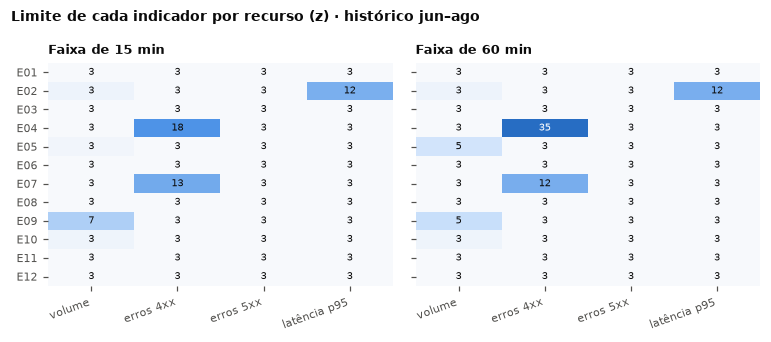

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1), sharey=True)
for ax, L in zip(axes, (15, 60)):
    v = lim[L]
    ax.imshow(np.log10(v.to_numpy()), cmap=CMAP_SEQ, vmin=np.log10(3), vmax=2, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            ax.text(j, i, f"{v.iat[i, j]:.0f}", ha="center", va="center", fontsize=6.3,
                    color="white" if np.log10(v.iat[i, j]) > 1.45 else TXT1)
    ax.set_xticks(range(v.shape[1]))
    ax.set_xticklabels(v.columns, rotation=20, ha="right")
    ax.set_yticks(range(v.shape[0]))
    ax.set_yticklabels(v.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"Faixa de {L} min", loc="left")
fig.suptitle("Limite de cada indicador por recurso (z) · histórico jun–ago", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout()
salvar(fig, "fig_limites")
plt.show()

## Limites com histórico de 3 meses × 1 mês (setembro, 15 min)
Razão entre o limite com 3 meses e com 1 mês. Valores > 1: o histórico longo inclui mais picos (ou mudanças de patamar) e fica mais tolerante.

In [6]:
l3 = calib[(PROPOSTO, 15, "set", "3m")]["limite"]
l1 = calib[(PROPOSTO, 15, "set", "1m")]["limite"]
razao_lim = (l3 / l1).rename(index=rot).rename(columns=INDICADOR).sort_index()
print("razão mediana 3m/1m por indicador:", razao_lim.median().round(2).to_dict())
razao_lim.round(2)

razão mediana 3m/1m por indicador: {'volume': 1.0, 'erros 4xx': 1.0, 'erros 5xx': 1.0, 'latência p95': 1.0}


,volume,erros 4xx,erros 5xx,latência p95
E01,1.00,1.00,1.0,1.00
E02,0.87,1.00,1.0,3.92
E03,1.00,1.00,1.0,1.00
E04,0.99,0.59,1.0,1.00
E05,1.08,1.00,1.0,1.00
E06,1.00,1.00,1.0,1.00
E07,1.00,2.48,1.0,1.00
E08,0.95,1.00,1.0,0.79
E09,2.13,1.00,1.0,0.89
E10,0.99,1.00,1.0,1.00


## Alarmes no histórico (fora da amostra)

In [7]:
alarmes = {k: float((c["razao_cal"] > c["c"]).mean()) for k, c in calib.items()}
alarmes = pd.Series(alarmes).unstack([2, 3])
alarmes.round(4)

ago             set        
                                   3m      1m      3m      1m
Perfil por contexto        15  0.1258  0.1428  0.1383  0.1340
                           30  0.1253  0.1416  0.1352  0.1308
                           60  0.1174  0.1375  0.1333  0.1287
Regimes normais (proposto) 15  0.0802  0.0988  0.0833  0.0872
                           30  0.0724  0.0950  0.0770  0.0776
                           60  0.0664  0.0915  0.0739  0.0709
Regimes sem contexto       15  0.0538  0.0755  0.0580  0.0677
                           30  0.0497  0.0721  0.0521  0.0609
                           60  0.0423  0.0664  0.0481  0.0563
Semana anterior            15  0.1111  0.1207  0.1190  0.1062
                           30  0.1120  0.1223  0.1208  0.1097
                           60  0.1114  0.1186  0.1221  0.1134
z-score global             15  0.1134  0.1187  0.1119  0.1061
                           30  0.1057  0.1115  0.1036  0.1007
                           60  0.0999  0.1057  0.0982  0.0977

## Residual real no histórico (60 min, proposto, setembro/3 meses): qual indicador?

In [8]:
per = periodo_treino("set", HIST_PRINCIPAL)
cal = calib[(PROPOSTO, 60, "set", HIST_PRINCIPAL)]
p = recortar(periodos[60], per)
tr1h = recortar(jan1h, per)
dobra_p, dobra_1h = dobras(p, per), dobras(tr1h, per)
vezes = pd.DataFrame(index=p.index, columns=ATRIBUTOS, dtype=float)
for k in range(4):
    m = METODOS[PROPOSTO]().ajustar(tr1h[dobra_1h != k], p[dobra_p != k])
    vezes.loc[dobra_p == k] = (z_direcional(m.z(p[dobra_p == k], cal["limite"])) / cal["limite"].reindex(p.loc[dobra_p == k, "recurso"]).to_numpy()).to_numpy()
res = (vezes > 1).any(axis=1)
ind = vezes[res].astype(float).idxmax(axis=1).map(INDICADOR)
print(f"{int(res.sum())} períodos residuais de 1 h em jun–ago ({res.mean():.1%})")
ind.value_counts()

1555 períodos residuais de 1 h em jun–ago (7.4%)


erros 4xx       534
volume          464
latência p95    407
erros 5xx       150
Name: count, dtype: int64

## Regimes normais do modelo de setembro (histórico de 3 meses)
Número de regimes, silhouette e quantos regimes são admissíveis, em média, em cada contexto.

In [9]:
mod_set = calib[(PROPOSTO, 60, "set", HIST_PRINCIPAL)]["modelo"]
tab_reg = pd.DataFrame({rot(r): dict(k=m["k"], silhouette=m["silhouette"], janelas=m["n"],
                                     admissiveis_por_contexto=m["adm"].sum(axis=2).mean(),
                                     contextos_com_mais_de_um=(m["adm"].sum(axis=2) > 1).mean())
                        for r, m in mod_set.rec.items()}).T.sort_index()
print("regimes por recurso: mediana", tab_reg["k"].median(), "· silhouette médio", round(tab_reg["silhouette"].astype(float).mean(), 2),
      "· regimes admissíveis por contexto (média)", round(tab_reg["admissiveis_por_contexto"].astype(float).mean(), 1))
nomes_reg = {rot(r): m["nomes"] for r, m in mod_set.rec.items()}
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame([(r, n) for r, dct in sorted(nomes_reg.items()) for n in dct.values()], columns=["recurso", "regime"]))
tab_reg.round(2)

regimes por recurso: mediana 3.5 · silhouette médio 0.51 · regimes admissíveis por contexto (média) 2.7


,recurso,regime
0,E01,"R1: volume baixo · todos os dias · 3–9h, 12–17h, 19–23h"
1,E01,"R2: volume médio, latência alta · dia útil · esporádico"
2,E01,"R3: volume médio, 4xx alto · todos os dias · esporádico"
3,E01,R4: volume alto · dia útil · esporádico
4,E01,"R5: volume alto · dia útil · 0–1h, 18h"
5,E02,R1: volume baixo · não útil · esporádico
6,E02,"R2: volume médio · todos os dias · 3–4h, 6h, 22–23h"
7,E02,"R3: volume médio, 5xx alto · dia útil · 0h"
8,E02,"R4: volume alto · dia útil · 8–17h, 19h"
9,E02,"R5: volume alto, latência alta · dia útil · esporádico"


,k,silhouette,janelas,admissiveis_por_contexto,contextos_com_mais_de_um
E01,5.0,0.39,2208.0,3.56,1.00
E02,5.0,0.55,1114.0,3.71,1.00
E03,4.0,0.52,1114.0,2.56,0.90
E04,2.0,0.60,2208.0,1.54,0.54
E05,2.0,0.75,2208.0,1.33,0.33
E06,2.0,0.64,1114.0,1.08,0.08
E07,2.0,0.61,2208.0,1.44,0.44
E08,5.0,0.36,2208.0,3.54,1.00
E09,3.0,0.62,2208.0,2.10,0.85
E10,8.0,0.29,1116.0,5.98,1.00


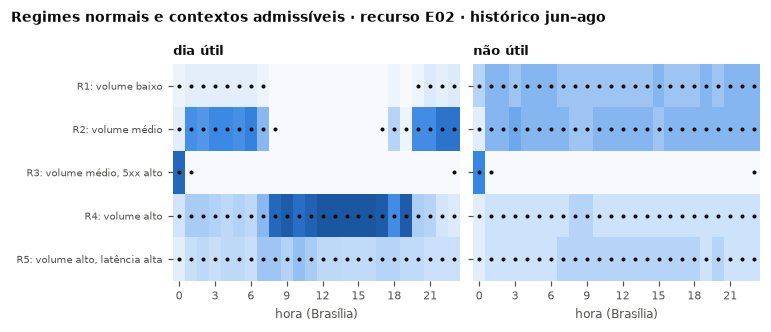

In [10]:
EXEMPLO = [r for r in mod_set.rec if rot(r) == "E02"][0]
m = mod_set.rec[EXEMPLO]
frac = m["frac"].fillna(0).to_numpy().reshape(2, 24, m["k"])
fig, axes = plt.subplots(1, 2, figsize=(7.0, 0.42 * m["k"] + 0.9), sharey=True)
for ax, (i_td, td) in zip(axes, enumerate(Regimes.DIAS)):
    v = frac[i_td].T  # regimes × horas
    ax.imshow(v, aspect="auto", cmap=CMAP_SEQ, vmin=0, vmax=1)
    ys, xs = np.nonzero(m["adm"][i_td].T)
    ax.scatter(xs, ys, s=7, color=TXT1, marker="o", linewidths=0)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("hora (Brasília)")
    ax.set_yticks(range(m["k"]))
    ax.set_yticklabels([m["nomes"][j].split(" · ")[0] for j in range(m["k"])], fontsize=6.5)
    ax.set_title(NOMES_DIA[td], loc="left")
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
fig.suptitle(f"Regimes normais e contextos admissíveis · recurso {rot(EXEMPLO)} · histórico jun–ago", x=0.01, ha="left",
             fontsize=9, fontweight="bold")
fig.tight_layout()
salvar(fig, "fig_regimes_admissiveis")
plt.show()

In [11]:
with open(RESULTADOS / "04_calibracao.pkl", "wb") as f:
    pickle.dump(calib, f)
pd.concat(lim, axis=1).to_csv(RESULTADOS / "04_limites.csv")
razao_lim.to_csv(RESULTADOS / "04_razao_limites_3m_1m.csv")
alarmes.to_csv(RESULTADOS / "04_alarmes_historico.csv")
tab_reg.to_csv(RESULTADOS / "04_regimes.csv")
salvar_json(nomes_reg, "04_nomes_regimes.json")
salvar_json({" | ".join(map(str, k)): round(c["c"], 3) for k, c in calib.items()}, "04_multiplicadores.json")
salvar_json(dict(residuais_60=int(res.sum()), frac=float(res.mean()), indicadores=ind.value_counts().to_dict(),
                 razao_lim_mediana=razao_lim.median().to_dict()), "04_resumo.json")